<h5>Enterrise Incident Investigation Agent</h5>

<p>Problem Statement Large enterprises run hundreds of production applications:</p>

<p>payment systems</p>
<p>authentication services</p>
<p>order management</p>
<p>customer APIs</p>
<p>internal microservices</p>

<p>When incidents happen:</p>
<p>APIs become slow<p>
<p>transactions fail
<p>users complain

<p>Operations and SRE teams must quickly determine:</p>
<p>what failed</p>
<p>hy it failed</p>
<p>whether deployment caused it</p>
<p>whether infrastructure is overloaded</p>
<p>which corrective actions are needed</p>

<p>Today investigation is mostly manual.</p>
Engineers jump across:

monitoring dashboards
logs
deployment tools
incident systems
infrastructure metrics
</p>

In [1]:
#Setup your env 
from dotenv import load_dotenv,find_dotenv
import os
load_dotenv()

True

In [2]:
api_key = os.getenv('OPENAI_API_KEY')


In [4]:
##import dependency
from datetime import datetime, timedelta
from typing import TypedDict, Annotated
import random

from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langchain_core.messages import (
    HumanMessage,
    SystemMessage,
    AIMessage
)

from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import ToolNode

In [ ]:
# ============================================================
# REALISTIC ENTERPRISE DATA
# ============================================================
# This has data form 2 payment systems (production)

INFRASTRUCTURE_DATA = {

    "payment-server-prod-01": {

        "environment": "production",
        "region": "ap-south-1",
        "service": "payment-service",

        "metrics": {
            "cpu_usage": 97,
            "memory_usage": 91,
            "disk_usage": 84,
            "network_latency_ms": 420,
            "active_connections": 1843,
            "request_per_minute": 28750,
            "error_rate": 18.4
        },

        "deployment_history": [
            {
                "timestamp": "2026-04-28 18:20:00",
                "version": "payment-service-v2.4.1",
                "deployed_by": "release-engineering",
                "change_summary": [
                    "Introduced Redis caching layer",
                    "Optimized DB connection pooling",
                    "Migrated payment reconciliation logic",
                    "Enabled async event processing"
                ],
                "deployment_status": "SUCCESS"
            },

            {
                "timestamp": "2026-04-25 10:15:00",
                "version": "payment-service-v2.3.8",
                "deployed_by": "platform-team",
                "change_summary": [
                    "Security patch upgrade",
                    "Dependency version updates"
                ],
                "deployment_status": "SUCCESS"
            }
        ],

        "application_logs": [
            {
                "timestamp": "2026-04-29 09:14:22",
                "severity": "ERROR",
                "message": "Database connection timeout after 30000ms"
            },
            {
                "timestamp": "2026-04-29 09:14:25",
                "severity": "WARNING",
                "message": "Redis cache miss ratio exceeded threshold"
            },
            {
                "timestamp": "2026-04-29 09:15:10",
                "severity": "ERROR",
                "message": "Connection pool exhausted"
            },
            {
                "timestamp": "2026-04-29 09:15:50",
                "severity": "CRITICAL",
                "message": "Payment transaction processing latency exceeded SLA"
            }
        ],

        "incidents": [
            {
                "incident_id": "INC-20451",
                "priority": "P1",
                "summary": "Payment API latency spike",
                "status": "OPEN",
                "created_at": "2026-04-29 08:55:00"
            }
        ]
    },

    "auth-server-prod-02": {

        "environment": "production",
        "region": "ap-south-1",
        "service": "authentication-service",

        "metrics": {
            "cpu_usage": 42,
            "memory_usage": 55,
            "disk_usage": 38,
            "network_latency_ms": 42,
            "active_connections": 540,
            "request_per_minute": 9400,
            "error_rate": 0.2
        },

        "deployment_history": [
            {
                "timestamp": "2026-04-20 11:10:00",
                "version": "auth-service-v1.8.4",
                "deployed_by": "security-team",
                "change_summary": [
                    "JWT token optimization",
                    "Added MFA enhancements"
                ],
                "deployment_status": "SUCCESS"
            }
        ],

        "application_logs": [
            {
                "timestamp": "2026-04-29 09:11:12",
                "severity": "INFO",
                "message": "Authentication successful"
            },
            {
                "timestamp": "2026-04-29 09:11:20",
                "severity": "INFO",
                "message": "Service health check passed"
            }
        ],

        "incidents": []
    }
}

In [ ]:
# ============================================================
# CUSTOM ENTERPRISE TOOLS
# ============================================================
# This will take server/ system name as input and go through the logs and if server name is not there in the log ruturn the server not found else 
# return the server metrics
@tool
def get_server_health(server_name: str) -> str:
    """
    Fetch overall server health metrics including CPU,
    memory, network latency, and error rate
    """
    if server_name not in INFRASTRUCTURE_DATA:
        return f"server {server_name} not found"
    metrics = INFRASTRUCTURE_DATA[server_name]['metrics']
    
    return f"""
    Server: {server_name}
    CPU Usage: {metrics['cpu_usage']}%
    Memory Usage: {metrics['memory_usage']}%
    Disk Usage: {metrics['disk_usage']}%
    Network Latency: {metrics['network_latency_ms']}%
    Active Connections: {metrics['active_connections']}
    Requests Per Minute: {metrics['request_per_minute']}
    Error Rate: {metrics['error_rate']}%
    """
    
    
    

In [9]:
# This tool will fetch recent application logs for a server.Severity can be:INFO, WARNING, ERROR, CRITICAL or ALL.
@tool
def get_recent_logs(server_name: str, severity: str = "ALL") -> str:
    """
    Fetch recent application logs for a server
    Severity can be:
    INFO,WARNING,ERROR,CRITICAL or ALL.
    """
    if server_name not in INFRASTRUCTURE_DATA:
        return f"Server {server_name} not found"
    logs = INFRASTRUCTURE_DATA[server_name]['application_logs']
    filtered_logs = []
    for log in logs:
        if severity == "ALL" or log['severity'] == severity:
            filtered_logs.append(
                f"""
                [{log['timestamp']}]
                [{log['severity']}]
                [{log['message']}]
                """
            )
    if not filtered_logs:
        return "No Matching logs found"
    return "\n".join(filtered_logs)
            
    
            
        
    

In [10]:
# This tool will fetch deployment history for a server.
@tool
def get_deployment_history(server_name: str) -> str:
    """
    Fetch the deployment history for the server.
    """
    if server_name not in INFRASTRUCTURE_DATA:
        return f"Server {server_name} not found"
    
    deployment_history = INFRASTRUCTURE_DATA[server_name]['deployment_history']
    result = []
    for deployment in deployment_history:
        deployment_text = f"""
        Timestamp: {deployment['timestamp']}
        Version: {deployment['version']}
        Deployed By: {deployment['deployed_by']}
        Deployment Status: {deployment['deployment_status']}
        Changes:
        """
        deployment_text += "\n".join(f"- {change}" for change in deployment["change_summary"])
        result.append(deployment_text)
    
    return "\n".join(result)
    
    
        
    
        
        
    
        
    

In [11]:
# Tool to fetch open incidents associated with a server.
@tool
def get_open_incidents(server_name: str) -> str:
    """
    Fetch open incidents associated with a server.
    """

    if server_name not in INFRASTRUCTURE_DATA:
        return f"Server {server_name} not found"

    incidents = INFRASTRUCTURE_DATA[server_name]["incidents"]

    if not incidents:
        return "No open incidents"

    result = []

    for incident in incidents:

        result.append(
            f"""
            Incident ID: {incident['incident_id']}
            Priority: {incident['priority']}
            Summary: {incident['summary']}
            Status: {incident['status']}
            Created At: {incident['created_at']}
            """
        )

    return "\n".join(result)

In [29]:
#  This toll will perform automated root cause analysis based on infrastructure metrics and logs.

@tool
def perform_root_cause_analysis(server_name: str) -> str:
    """
    Perform automated root cause analysis based on
    infrastructure metrics and logs.
    """

    if server_name not in INFRASTRUCTURE_DATA:
        return f"Server {server_name} not found"

    metrics = INFRASTRUCTURE_DATA[server_name]["metrics"]

    findings = []

    if metrics["cpu_usage"] > 90:
        findings.append(
            "CPU utilization is critically high."
        )

    if metrics["memory_usage"] > 85:
        findings.append(
            "Memory utilization indicates resource exhaustion."
        )

    if metrics["error_rate"] > 10:
        findings.append(
            "Application error rate exceeded operational threshold."
        )

    if metrics["network_latency_ms"] > 300:
        findings.append(
            "Network latency is significantly elevated."
        )

    findings.append(
        "Recent deployment may have contributed to instability."
    )

    return "\n".join(findings)

In [14]:
# ============================================================
# TOOLS
# ============================================================
tools = [
    get_server_health,
    get_recent_logs,
    get_deployment_history,
    get_open_incidents,
    perform_root_cause_analysis
    
]

In [15]:
# ============================================================
# LLM
# ============================================================
llm = ChatOpenAI(temperature=0, model_name="gpt-4o-mini")
llm_with_tools = llm.bind_tools(tools)

In [19]:
# ============================================================
# STATE
# ============================================================
class StateAgent(TypedDict):
    messages:Annotated[list, add_messages]

In [30]:
# ============================================================
# SYSTEM PROMPT
# ============================================================

system_prompt = SystemMessage(
    content="""
You are an Enterprise IT Incident Investigation Agent.

Your responsibilities include:
- production incident investigation
- deployment impact analysis
- infrastructure diagnostics
- root cause analysis
- operational recommendations

after calling tools which includes responsibilites 
call the tool
- perform_root_cause_analysis 
before generating the final response


Guidelines:
1. Investigate systematically.
2. Correlate logs, deployments and metrics.
3. Use tools extensively before concluding.
4. Explain findings clearly for SRE and operations teams.
5. Mention probable causes and recommended actions.
"""
)

In [31]:
# ============================================================
# AGENT NODE
# ============================================================
def agent_node(state:StateAgent):
    messages = [system_prompt] + state['messages']
    response = llm_with_tools.invoke(messages)
    return {
        "messages": [response]
    }

In [32]:
# ============================================================
# TOOL NODE
# ============================================================

tool_node = ToolNode(tools)

In [33]:
# ============================================================
# ROUTING
# ============================================================

def should_continue(state: StateAgent):

    last_message = state["messages"][-1]

    if isinstance(last_message, AIMessage) and last_message.tool_calls:
        return "tools"

    return "end"

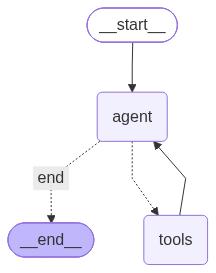

In [34]:
# ============================================================
# BUILD GRAPH
# ============================================================
graph_builder = StateGraph(StateAgent)
graph_builder.add_node("agent",agent_node)
graph_builder.add_node("tools",tool_node)
graph_builder.set_entry_point("agent")
graph_builder.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",
        "end": END
    }
)
graph_builder.add_edge("tools","agent")
graph = graph_builder.compile()
graph

In [35]:
query = """
Payment API latency has increased significantly.
Customers are reporting transaction failures.

Server Name: payment-server-prod-01

Investigate the issue thoroughly and provide:
- probable root cause
- deployment correlation
- infrastructure observations
- recommendations
"""

response = graph.invoke(
    {
        "messages": [
            HumanMessage(content=query)
        ]
    }
)

In [36]:
print("\n================ AGENT EXECUTION TRACE ================\n")

for message in response["messages"]:

    print(f"\n{message.type.upper()}")
    print("-" * 80)

    print(message.content)

    if hasattr(message, "tool_calls") and message.tool_calls:
        print("\nTOOL CALLS:")
        print(message.tool_calls)


================ AGENT EXECUTION TRACE ================


HUMAN
--------------------------------------------------------------------------------

Payment API latency has increased significantly.
Customers are reporting transaction failures.

Server Name: payment-server-prod-01

Investigate the issue thoroughly and provide:
- probable root cause
- deployment correlation
- infrastructure observations
- recommendations


AI
--------------------------------------------------------------------------------


TOOL CALLS:
[{'name': 'get_server_health', 'args': {'server_name': 'payment-server-prod-01'}, 'id': 'call_DPzRrbPHC8oGZXJH2Lj9SdnT', 'type': 'tool_call'}, {'name': 'get_recent_logs', 'args': {'server_name': 'payment-server-prod-01', 'severity': 'ERROR'}, 'id': 'call_hyGLQfVESPcNGBtgm24HlMJD', 'type': 'tool_call'}, {'name': 'get_deployment_history', 'args': {'server_name': 'payment-server-prod-01'}, 'id': 'call_PtmR2a8jjCoVMdemPVaekPpm', 'type': 'tool_call'}, {'name': 'get_open_incidents